In [1]:

import sys
if "google.colab" in sys.modules:
    !git clone -q https://github.com/jratchfo/learn_ocean_slab.git /content/learn_ocean_slab 2>/dev/null || git -C /content/learn_ocean_slab pull -q
    %pip install -q omegaconf
    sys.path.insert(0, "/content/learn_ocean_slab/src")

In [2]:
from dataclasses import replace

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from matplotlib.colors import LinearSegmentedColormap
from IPython.display import Video

from learn_ocean_slab.config import CONFIG_DIR, MOVIE_DIR, load_config
from learn_ocean_slab.movie import make_movie
from learn_ocean_slab.pm_slab import run

## Pollard-Millard Slab Model (1970)

The mixed layer is a slab of depth $H$ moving as one block with velocity $(u, v)$. It is pushed by the wind stress $(\tau_x, \tau_y)$, turned by the Coriolis parameter $f$, and damped at rate $r$:

$$\frac{du}{dt} - f v = T_x - r u$$

$$\frac{dv}{dt} + f u = T_y - r v$$

where $T_x = \tau_x/(\rho H)$ and $T_y = \tau_y/(\rho H)$.

**From $\mathbb{R}^2$ to $\mathbb{C}$.** Identify each vector $(a, b)$ with the complex number $a + ib$, and define

$$s \equiv u + iv, \qquad T \equiv T_x + i T_y$$

Multiply the $v$ equation by $i$ and add it to the $u$ equation:

$$\frac{d}{dt}(u + iv) + (i f u - f v) = (T_x + i T_y) - r\,(u + iv)$$

Because $i^2 = -1$, the Coriolis terms are $i f u - f v = i f (u + i v) = i f s$, so the two real equations become one complex equation:

$$\frac{ds}{dt} + (r + i f)\, s = T$$

Under this identification, multiplying by $-i$ rotates a vector $90^\circ$ clockwise, and multiplying by $e^{-i f t}$ rotates it clockwise by angle $f t$.

**Solution for constant $T$.** The homogeneous solution is $s_h = A\, e^{-(r + i f) t}$. A constant particular solution satisfies $(r + i f)\, s_s = T$, so

$$s_s = \frac{T}{r + i f}$$

Adding them and imposing $s(0) = s_0$ gives $A = s_0 - s_s$:

$$s(t) = s_s + (s_0 - s_s)\, e^{-r t}\, e^{-i f t}$$

The departure from the steady state rotates clockwise at frequency $f$ and decays at rate $r$.

**Back to $\mathbb{R}^2$.** The velocity components are $u = \mathrm{Re}(s)$ and $v = \mathrm{Im}(s)$. Multiplying the top and bottom of $s_s$ by $r - i f$ gives the steady state in components:

$$u_s = \frac{r\, T_x + f\, T_y}{r^2 + f^2}, \qquad v_s = \frac{r\, T_y - f\, T_x}{r^2 + f^2}$$

In [3]:
# Load a configuration and run the model
# see the model at src/learn_ocean_slab/pm_slab.py
config = load_config(CONFIG_DIR / "midlat_45N.yaml")
results = run(config)
results

<xarray.Dataset> Size: 150kB
Dimensions:        (time: 1440)
Coordinates:
  * time           (time) float64 12kB 0.0 600.0 1.2e+03 ... 8.628e+05 8.634e+05
Data variables:
    u              (time) float64 12kB 0.1 0.107 0.1136 ... 0.02127 0.02102
    v              (time) float64 12kB 0.1 0.09346 0.08651 ... -0.02182 -0.0231
    tau_x          (time) float64 12kB 0.1 0.1 0.1 0.1 0.1 ... 0.1 0.1 0.1 0.1
    tau_y          (time) float64 12kB 0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0
    u_steady       (time) float64 12kB 0.0004245 0.0004245 ... 0.0004245
    v_steady       (time) float64 12kB -0.01891 -0.01891 ... -0.01891 -0.01891
    M_x            (time) float64 12kB 5.0 5.351 5.68 ... 1.072 1.064 1.051
    M_y            (time) float64 12kB 5.0 4.673 4.325 ... -1.026 -1.091 -1.155
    wind_work      (time) float64 12kB 0.01 0.0107 0.01136 ... 0.002127 0.002102
    angle_to_wind  (time) float64 12kB 45.0 41.13 37.29 ... -43.76 -45.73 -47.7
    x              (time) float64 12kB 0.0 62.13 128.3 ... 1.564e+03 1.577e+03
    y              (time) float64 12kB 0.0 58.06 112.1 ... -1.705e+04 -1.707e+04
Attributes: (12/17)
    model:                pollard_millard
    lat:                  45.0
    H:                    50.0
    rho:                  1025.0
    tau_x:                0.1
    tau_y:                0.0
    ...                   ...
    wind_type:            steady
    wind_period_hours:    inf
    wind_duration_hours:  inf
    gust_std:             0.0
    gust_hours:           1.0
    seed:                 0

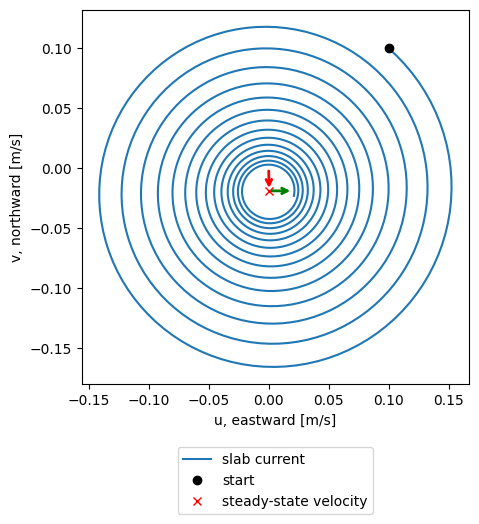

In [4]:
# Velocity hodograph

s_steady = results.u_steady[-1] + 1j * results.v_steady[-1]  # steady-state velocity [m/s]
wind = results.tau_x[-1] + 1j * results.tau_y[-1]  # wind stress [N/m^2]
wind_arrow = 0.02 * wind / abs(wind)  # only its direction is meaningful

fig, ax = plt.subplots(1, 1, figsize=(5, 5))
ax.plot(results.u, results.v, label="slab current")
ax.plot(results.u[0], results.v[0], "ko", label="start")
ax.plot(s_steady.real, s_steady.imag, "rx", label="steady-state velocity")
ax.annotate("", xy=(s_steady.real, s_steady.imag), xytext=(0, 0),
            arrowprops=dict(arrowstyle="->", color="red", lw=2))
ax.annotate("", xy=(s_steady.real + wind_arrow.real, s_steady.imag + wind_arrow.imag),
            xytext=(s_steady.real, s_steady.imag),
            arrowprops=dict(arrowstyle="->", color="green", lw=2))
ax.set_aspect("equal")
ax.set_xlabel("u, eastward [m/s]")
ax.set_ylabel("v, northward [m/s]")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15))

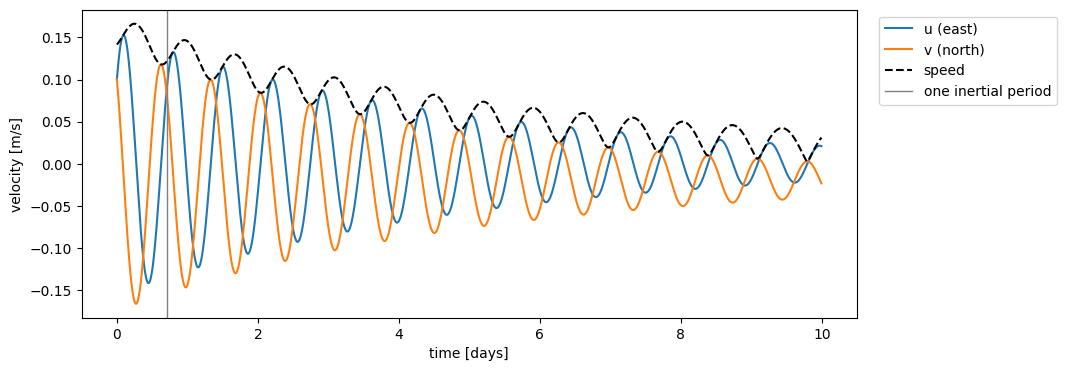

In [5]:
# Velocity over time

days = results.time / 86400

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(days, results.u, label="u (east)")
ax.plot(days, results.v, label="v (north)")
ax.plot(days, np.hypot(results.u, results.v), "k--", label="speed")
ax.axvline(config.inertial_period / 86400, color="gray", lw=1, label="one inertial period")
ax.set_xlabel("time [days]")
ax.set_ylabel("velocity [m/s]")
ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1))

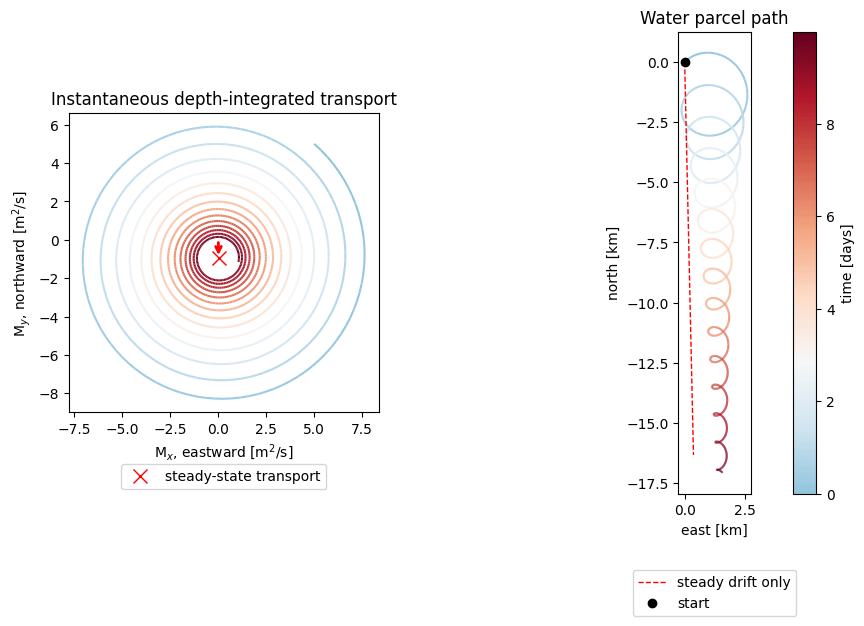

In [6]:
# Transport hodograph and water parcel path, colored by time

def time_colored_line(ax, x, y, days, cmap):
    """Draw the path (x, y) as a line colored by time."""
    points = np.column_stack([x, y])
    segments = np.stack([points[:-1], points[1:]], axis=1)
    line = LineCollection(segments, cmap=cmap, linewidths=1.5)
    line.set_array(days[:-1])
    ax.add_collection(line)
    ax.autoscale()
    return line


M_steady = config.H * s_steady  # steady-state transport [m^2/s]
steady_drift = s_steady * results.time  # path with no inertial oscillation [m]

# Light (early) to dark (late)
time_cmap = LinearSegmentedColormap.from_list("time", plt.cm.RdBu_r(np.linspace(0.3, 1, 256)))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 6))

time_colored_line(ax1, results.M_x, results.M_y, days, time_cmap)
ax1.plot(M_steady.real, M_steady.imag, "rx", markersize=10, label="steady-state transport")
ax1.annotate("", xy=(M_steady.real, M_steady.imag), xytext=(0, 0),
             arrowprops=dict(arrowstyle="->", color="red", lw=2))
ax1.set_aspect("equal")
ax1.set_xlabel("M$_x$, eastward [m$^2$/s]")
ax1.set_ylabel("M$_y$, northward [m$^2$/s]")
ax1.set_title("Instantaneous depth-integrated transport")
ax1.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15))

line = time_colored_line(ax2, results.x / 1000, results.y / 1000, days, time_cmap)
ax2.plot(steady_drift.real / 1000, steady_drift.imag / 1000, "r--", lw=1, label="steady drift only")
ax2.plot(0, 0, "ko", label="start")
ax2.set_aspect("equal")
ax2.set_xlabel("east [km]")
ax2.set_ylabel("north [km]")
ax2.set_title("Water parcel path")
ax2.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15))

fig.colorbar(line, ax=[ax1, ax2], label="time [days]")

## Comparisons

Each run starts from rest and changes one setting from the base config with `dataclasses.replace`.

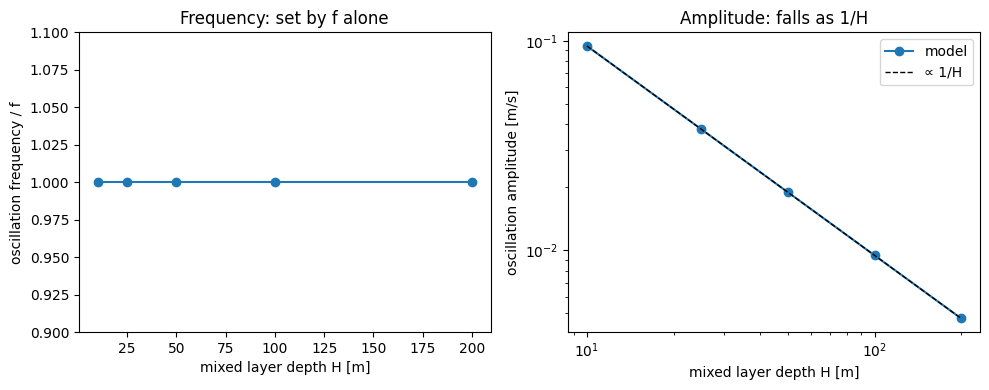

In [7]:
# Mixed layer depth: oscillation frequency and size

depths = [10.0, 25.0, 50.0, 100.0, 200.0]  # [m]
base = replace(config, u_initial=0.0, v_initial=0.0, duration_days=5.0)

frequency, amplitude = [], []
for H in depths:
    run_H = run(replace(base, H=H))
    s = run_H.u + 1j * run_H.v
    oscillation = (s - (run_H.u_steady + 1j * run_H.v_steady)).values  # departure from steady state
    phase = np.unwrap(np.angle(oscillation))
    frequency.append(-np.polyfit(run_H.time, phase, 1)[0])  # clockwise rotation rate [rad/s]
    amplitude.append(abs(oscillation[0]))  # starting size of the oscillation [m/s]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
ax1.plot(depths, np.array(frequency) / config.f, "o-")
ax1.set_ylim(0.9, 1.1)
ax1.set_xlabel("mixed layer depth H [m]")
ax1.set_ylabel("oscillation frequency / f")
ax1.set_title("Frequency: set by f alone")
ax2.loglog(depths, amplitude, "o-", label="model")
ax2.loglog(depths, amplitude[0] * depths[0] / np.array(depths), "k--", lw=1, label="∝ 1/H")
ax2.set_xlabel("mixed layer depth H [m]")
ax2.set_ylabel("oscillation amplitude [m/s]")
ax2.set_title("Amplitude: falls as 1/H")
ax2.legend()
fig.tight_layout()

### Comparing a steady wind foricng at different latitudes.

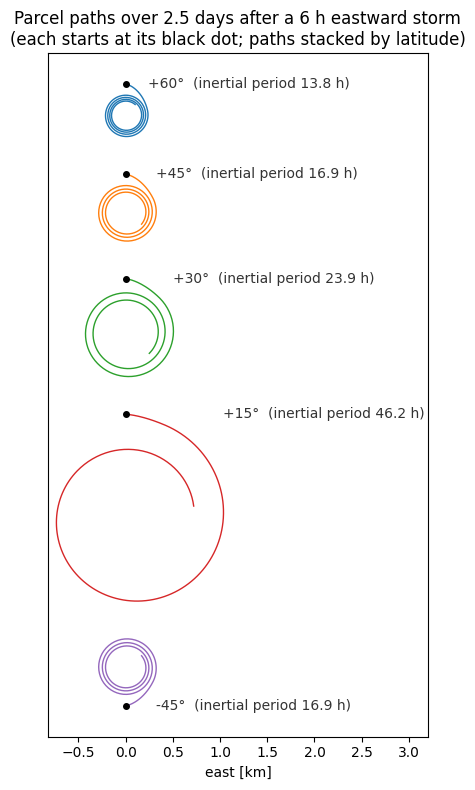

In [8]:
# Same 6-hour eastward storm at different latitudes: water parcel paths

base = replace(config, u_initial=0.0, v_initial=0.0, wind_duration_hours=6.0, duration_days=2.5)
latitudes = [60.0, 45.0, 30.0, 15.0, -45.0]  # top to bottom
gap = 0.4  # space between neighboring paths [km]

fig, ax = plt.subplots(figsize=(7, 8))
bottom_of_previous = 0.0
for lat in latitudes:
    run_lat = run(replace(base, lat=lat))
    x, y = run_lat.x / 1000, run_lat.y / 1000  # [km]
    offset = bottom_of_previous - gap - float(y.max())  # stack each path below the last one
    bottom_of_previous = offset + float(y.min())
    period_hours = replace(base, lat=lat).inertial_period / 3600
    line, = ax.plot(x, y + offset, lw=1)
    ax.plot(0, offset, "ko", ms=4)
    ax.text(float(x.max()) , offset, f"{lat:+.0f}°  (inertial period {period_hours:.1f} h)",
            va="center", color="0.2", fontsize=10)
ax.set_aspect("equal")
ax.set_xlim(right=3.2)
ax.set_yticks([])
ax.set_xlabel("east [km]")
ax.set_title("Parcel paths over 2.5 days after a 6 h eastward storm\n(each starts at its black dot; paths stacked by latitude)")
fig.tight_layout()

### Comparing different Time-dependent winds at 45 degrees N (midlatitiude)

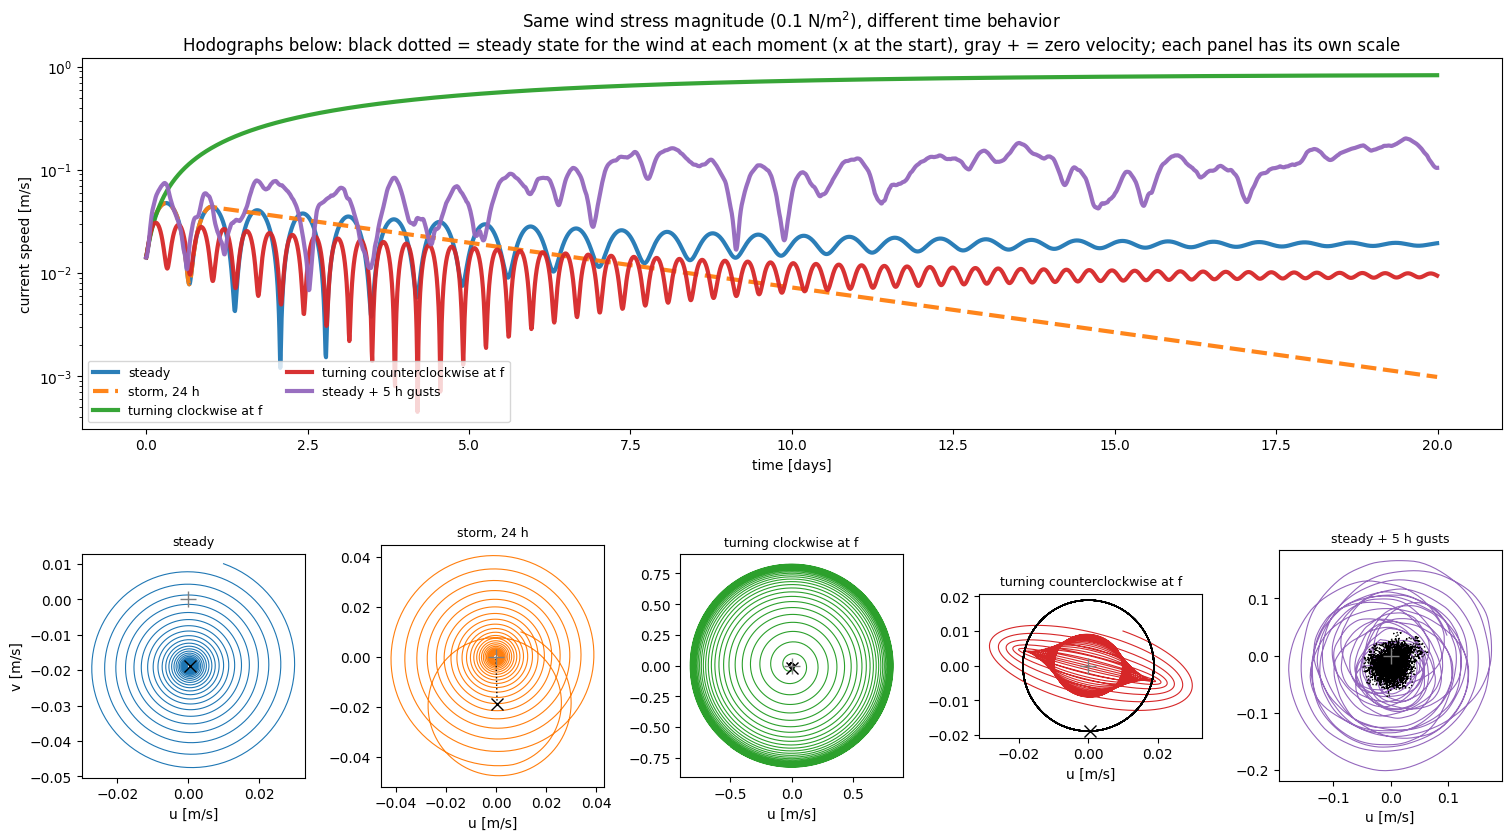

In [13]:
# Different winds of the same strength at 45

period = config.inertial_period / 3600  # inertial period [hours]
base = replace(config, u_initial=0.01, v_initial=0.01, duration_days=20.0)
winds = {
    "steady": base,
    "storm, 24 h": replace(base, wind_duration_hours=24),
    "turning clockwise at f": replace(base, wind_type="rotating", wind_period_hours=period),
    "turning counterclockwise at f": replace(base, wind_type="rotating", wind_period_hours=-period),
    "steady + 5 h gusts": replace(base, gust_std=0.1, gust_hours=5.0),
}

runs = {}  # kept for the cells below
fig = plt.figure(figsize=(15, 8.5), layout="constrained")
grid = fig.add_gridspec(2, len(winds), height_ratios=[1, 1])
ax = fig.add_subplot(grid[0, :])
for column, (label, wind_config) in enumerate(winds.items()):
    run_wind = runs[label] = run(wind_config)
    color = f"C{column}"
    style = "--" if "storm" in label else "-"  # dashed so the steady line shows through while they overlap
    ax.plot(run_wind.time / 86400, np.hypot(run_wind.u, run_wind.v), style, color=color, lw=3, label=label, alpha=0.95)

    # Hodograph: each panel has its own scale, since the speeds differ by ~100x
    ax_hodo = fig.add_subplot(grid[1, column])
    ax_hodo.plot(run_wind.u, run_wind.v, color=color, lw=0.8)
    ax_hodo.plot(run_wind.u_steady, run_wind.v_steady, "k:", lw=1)  # moves when the wind changes
    ax_hodo.plot(run_wind.u_steady[0], run_wind.v_steady[0], "kx", ms=8)
    ax_hodo.plot(0, 0, "+", color="0.5", ms=12)
    ax_hodo.set_aspect("equal")
    ax_hodo.set_title(label, fontsize=9)
    ax_hodo.set_xlabel("u [m/s]")
    if column == 0:
        ax_hodo.set_ylabel("v [m/s]")
ax.set_yscale("log")
ax.set_xlabel("time [days]")
ax.set_ylabel("current speed [m/s]")
ax.set_title(f"Same wind stress magnitude ({config.tau_x} N/m$^2$), different time behavior\n"
             "Hodographs below: black dotted = steady state for the wind at each moment (x at the start), gray + = zero velocity; each panel has its own scale")
ax.legend(loc="lower left", ncol=2, fontsize=9)

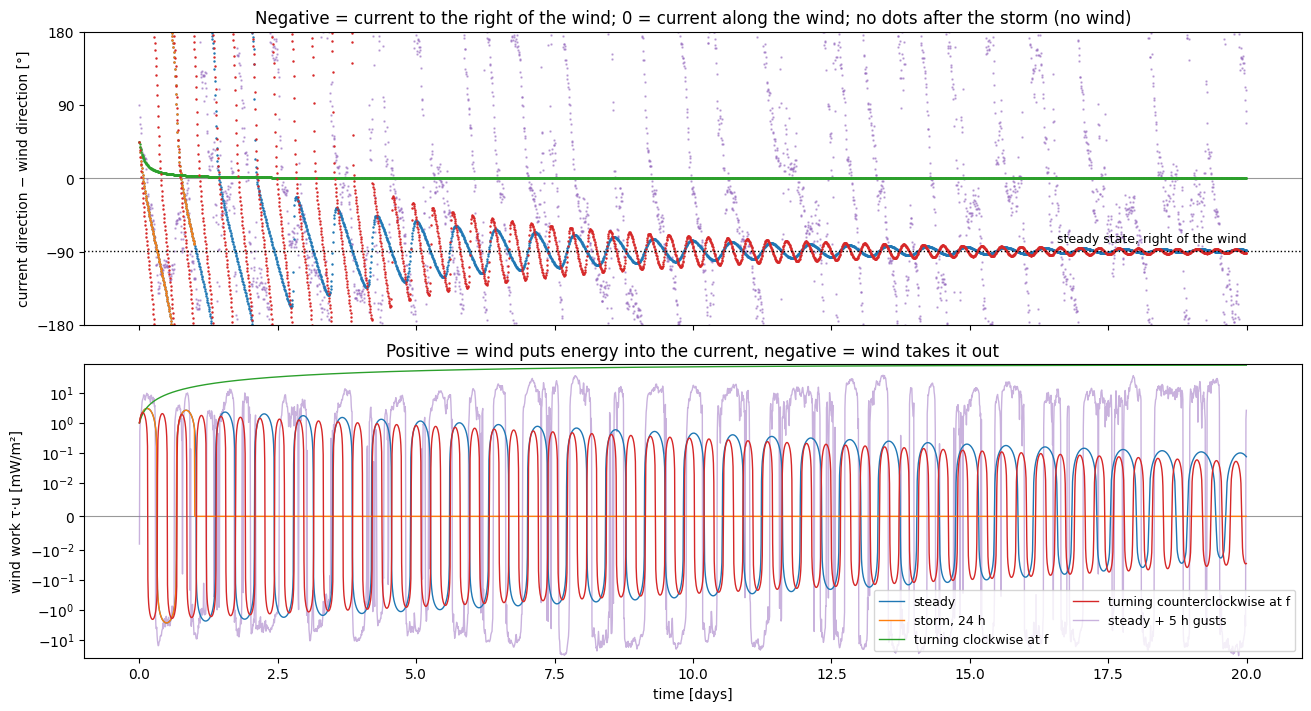

In [14]:
# Direction of the current relative to the wind, and the energy the wind puts in (same runs as above)

fig, (ax_angle, ax_work) = plt.subplots(2, 1, figsize=(13, 7), sharex=True, layout="constrained")
for column, (label, run_wind) in enumerate(runs.items()):
    days = run_wind.time / 86400
    behind = {"zorder": 1, "alpha": 0.5} if "gust" in label else {"zorder": 2}  # gusts are noisy; keep them behind
    # dots, not a line: the angle jumps from -180 to 180 and a line would draw that jump
    ax_angle.plot(days, run_wind.angle_to_wind, ".", color=f"C{column}", ms=1.5, **behind)
    ax_work.plot(days, run_wind.wind_work * 1000, color=f"C{column}", lw=1, label=label, **behind)

ax_angle.axhline(-np.degrees(np.arctan2(config.f, config.r)), color="k", ls=":", lw=1, zorder=3)
ax_angle.text(20, -82, "steady state, right of the wind", ha="right", va="bottom", fontsize=9)
ax_angle.axhline(0, color="0.6", lw=0.8, zorder=0)
ax_angle.set(ylim=(-180, 180), yticks=[-180, -90, 0, 90, 180],
             ylabel="current direction − wind direction [°]",
             title="Negative = current to the right of the wind; 0 = current along the wind; no dots after the storm (no wind)")
ax_work.axhline(0, color="0.6", lw=0.8, zorder=0)
ax_work.set_yscale("symlog", linthresh=0.01)  # log beyond ±0.01 mW/m², linear near zero
ax_work.set(xlabel="time [days]", ylabel="wind work τ·u [mW/m²]",
            title="Positive = wind puts energy into the current, negative = wind takes it out")
ax_work.legend(loc="lower right", ncol=2, fontsize=9)


### Creating a movie.

In [15]:
# Movie of the counterclockwise run: saved in movies/, plays below

movie_path = make_movie(runs["turning counterclockwise at f"], MOVIE_DIR / "counterclockwise_at_f.mp4")
Video(movie_path, embed=True, html_attributes="controls loop")


In [12]:
# Movie of the clockwise run: saved in movies/, plays below

movie_path = make_movie(runs["turning clockwise at f"], MOVIE_DIR / "clockwise_at_f.mp4")
Video(movie_path, embed=True, html_attributes="controls loop")


In [16]:


movie_path = make_movie(runs["steady"], MOVIE_DIR / "steady.mp4")
Video(movie_path, embed=True, html_attributes="controls loop")
